# 01 - Análise Exploratória
Este notebook apresenta a avaliação inicial do dataset WineQT, com foco em distribuição das variáveis, qualidade dos dados, correlação e a definição da variável alvo para a classificação binária.


In [1]:
from pathlib import Path

import pandas as pd

data_path = Path("../data/WineQT.csv")
df = pd.read_csv(data_path)

print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
print("\nTipos de dados:")
print(df.dtypes.to_string())
print("\nValores ausentes por coluna:")
missing = df.isna().sum()
print(missing[missing > 0].to_string())
print(f"\nDuplicatas: {df.duplicated().sum()}")

Linhas: 1143 | Colunas: 13

Tipos de dados:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Id                        int64

Valores ausentes por coluna:
Series([], )

Duplicatas: 0


## Definição da variável alvo

A regra do enunciado foi aplicada para transformar a qualidade em um problema binário:

- alta qualidade: `quality >= 7`
- baixa ou média qualidade: `quality < 7`

Essa decisão foi usada de forma consistente em toda a análise e na comparação entre modelos.


Contagem por classe:
target
0    984
1    159

Proporção da classe positiva: 13.91%


/tmp/ipykernel_8794/154373698.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="target", palette="Set2")


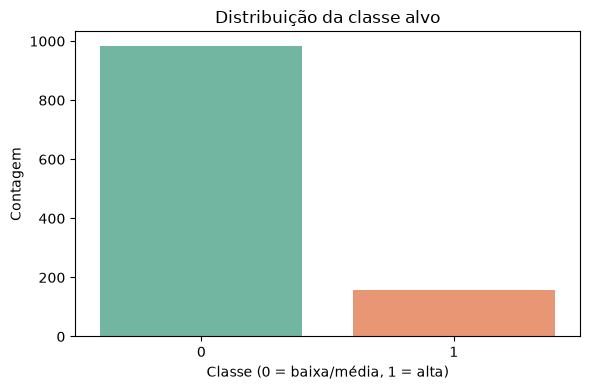

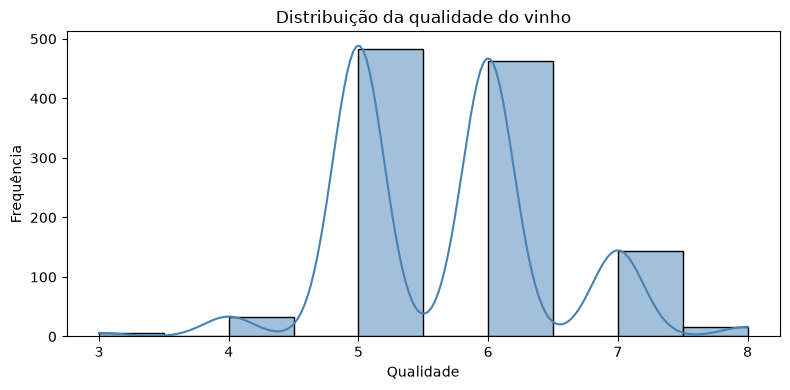

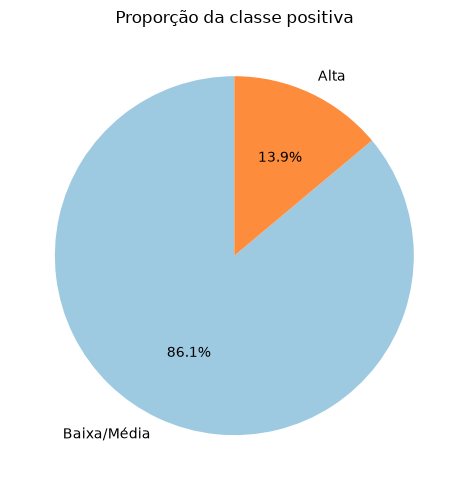

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# regra definida para o desafio: alta qualidade = quality >= 7
df["target"] = (df["quality"] >= 7).astype(int)
target_counts = df["target"].value_counts().sort_index()

print("Contagem por classe:")
print(target_counts.to_string())
print(f"\nProporção da classe positiva: {target_counts.get(1, 0) / len(df):.2%}")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="target", palette="Set2")
plt.title("Distribuição da classe alvo")
plt.xlabel("Classe (0 = baixa/média, 1 = alta)")
plt.ylabel("Contagem")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.histplot(df["quality"], bins=10, kde=True, color="steelblue")
plt.title("Distribuição da qualidade do vinho")
plt.xlabel("Qualidade")
plt.ylabel("Frequência")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
ax = plt.gca()
ax.pie(
    target_counts.values,
    labels=["Baixa/Média", "Alta"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#9ecae1", "#fd8d3c"],
)
ax.set_title("Proporção da classe positiva")
plt.tight_layout()
plt.show()

## Correlação, distribuição e sinais de decisão

A partir da matriz de correlação e da comparação por classe, é possível identificar quais variáveis têm relação mais forte com a qualidade e com o comportamento do conjunto. Esse passo ajuda a justificar o uso de métricas adequadas para dados desbalanceados e a entender por que certos modelos melhoram a classificação da classe positiva.


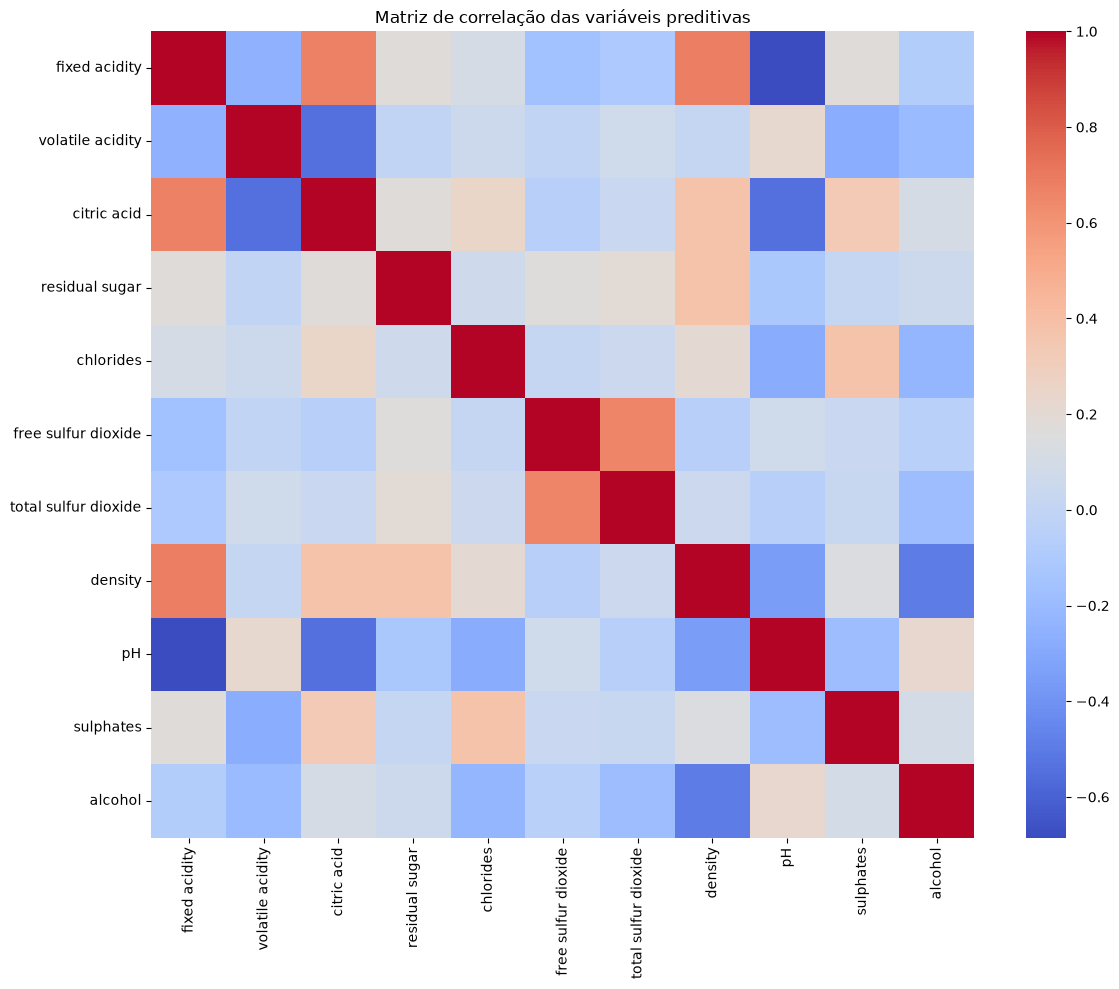

/tmp/ipykernel_8794/1177528277.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="target", y="alcohol", palette="Set2")


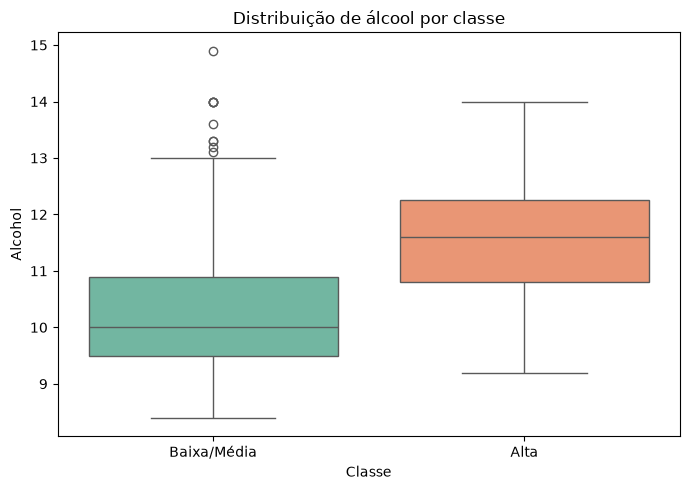

Nenhum valor ausente encontrado no conjunto.


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = df.drop(columns=["Id", "quality", "target"]).corr(numeric_only=True)

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=False, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlação das variáveis preditivas")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="target", y="alcohol", palette="Set2")
plt.title("Distribuição de álcool por classe")
plt.xlabel("Classe")
plt.ylabel("Alcohol")
plt.xticks([0, 1], ["Baixa/Média", "Alta"])
plt.tight_layout()
plt.show()

missing_plot = df.isna().sum().sort_values(ascending=False)
missing_plot = missing_plot[missing_plot > 0]

if not missing_plot.empty:
    plt.figure(figsize=(8, 4))
    sns.barplot(x=missing_plot.index, y=missing_plot.values, palette="crest")
    plt.title("Valores ausentes por variável")
    plt.xticks(rotation=45)
    plt.ylabel("Quantidade")
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum valor ausente encontrado no conjunto.")

## Outliers das variáveis físico-químicas

Como parte do EDA, avaliamos possíveis outliers com boxplots e também quantificamos a proporção de pontos fora dos limites do método IQR (Q1 - 1.5*IQR e Q3 + 1.5*IQR).

Nesta etapa, o objetivo é diagnóstico. A remoção ou tratamento deve ser validada depois na modelagem para evitar perda de sinal relevante da classe positiva.


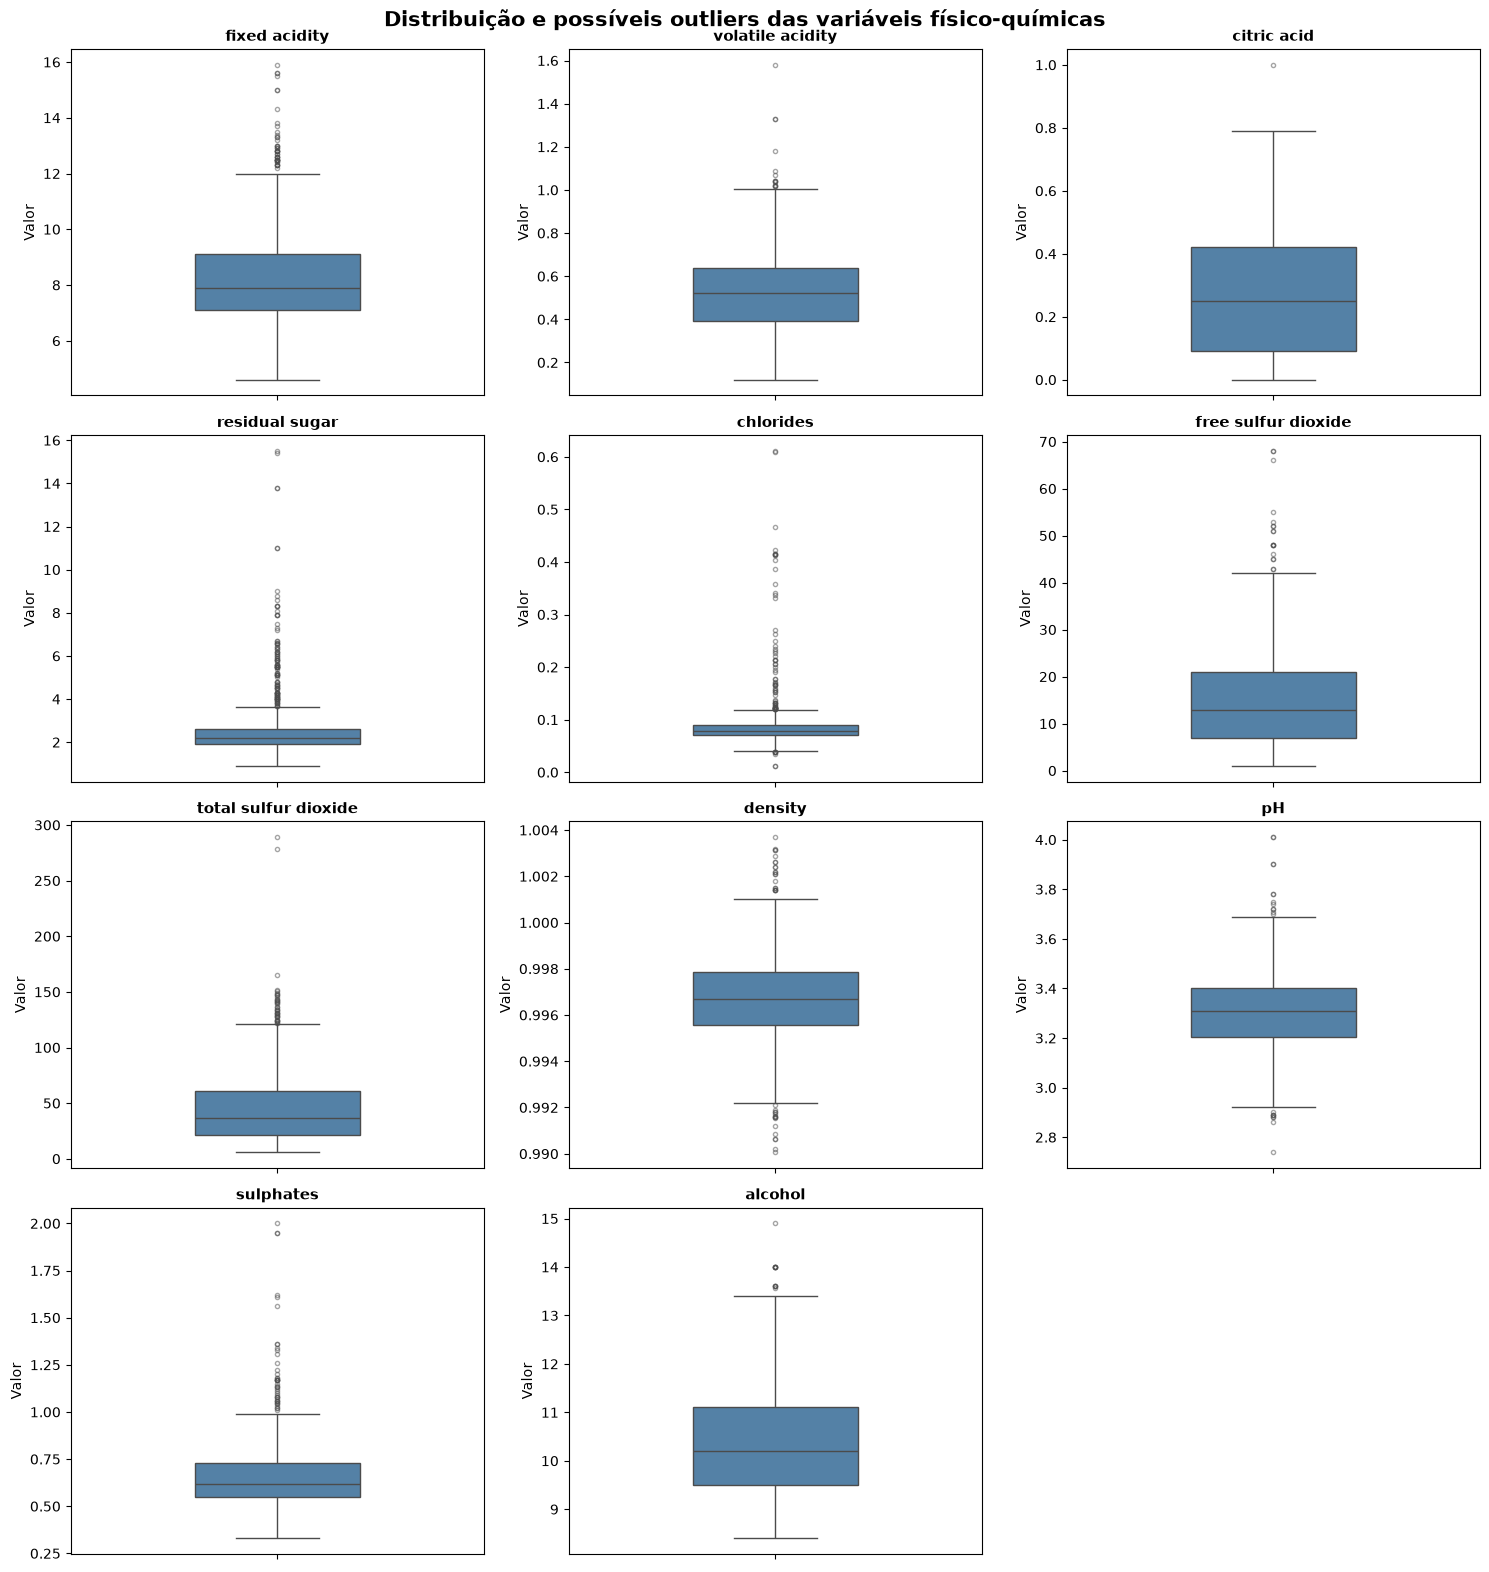

Resumo de outliers (critério IQR):


,variavel,limite_inferior,limite_superior,qtd_outliers,perc_outliers
3,residual sugar,0.850000,3.650000,110,9.62%
4,chlorides,0.040000,0.120000,77,6.74%
0,fixed acidity,4.100000,12.100000,44,3.85%
9,sulphates,0.280000,1.000000,43,3.76%
6,total sulfur dioxide,-39.000000,121.000000,40,3.50%
7,density,0.992157,1.001257,36,3.15%
8,pH,2.912500,3.692500,20,1.75%
5,free sulfur dioxide,-14.000000,42.000000,18,1.57%
1,volatile acidity,0.021250,1.011250,14,1.22%
10,alcohol,7.100000,13.500000,12,1.05%


In [4]:
colunas = [
    "fixed acidity", "volatile acidity", "citric acid",
    "residual sugar", "chlorides", "free sulfur dioxide",
    "total sulfur dioxide", "density", "pH", "sulphates",
    "alcohol"
]

ncols = 3
nrows = (len(colunas) + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for i, coluna in enumerate(colunas):
    sns.boxplot(
        data=df,
        y=coluna,
        ax=axes[i],
        color="steelblue",
        width=0.4,
        flierprops={"marker": "o", "markersize": 3, "alpha": 0.5},
    )
    axes[i].set_title(coluna, fontsize=11, fontweight="bold")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Valor")

for ax in axes[len(colunas):]:
    ax.set_visible(False)

fig.suptitle(
    "Distribuição e possíveis outliers das variáveis físico-químicas",
    fontsize=15,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

outlier_summary = []
for coluna in colunas:
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr

    mask_outlier = (df[coluna] < lim_inf) | (df[coluna] > lim_sup)
    qtd_outliers = int(mask_outlier.sum())
    perc_outliers = 100 * qtd_outliers / len(df)

    outlier_summary.append(
        {
            "variavel": coluna,
            "limite_inferior": lim_inf,
            "limite_superior": lim_sup,
            "qtd_outliers": qtd_outliers,
            "perc_outliers": perc_outliers,
        }
    )

outlier_df = pd.DataFrame(outlier_summary).sort_values(
    by="perc_outliers", ascending=False
)
print("Resumo de outliers (critério IQR):")
display(outlier_df.style.format({"perc_outliers": "{:.2f}%"}))

## Interpretação do EDA

A análise exploratória confirma que a classe de alta qualidade é minoritária no dataset, o que torna relevante usar métricas como F1 e recall em vez de confiar somente em acurácia.

A variável `alcohol` mostra diferença clara entre as classes, e a matriz de correlação reforça que o problema depende de combinações de variáveis, não de uma única feature isolada. A análise de outliers por boxplot e IQR também mostrou caudas importantes em variáveis como sulfur dioxide, chlorides e residual sugar, o que orienta o cuidado com escalonamento e robustez dos modelos.

Além disso, a estrutura dos dados foi validada antes do treino, com ausência de valores ausentes relevantes e sem observações duplicadas.
